In [22]:
import torch
from torch.distributions import Distribution, Normal
import math
import numpy as np
from KDE_prior_estimation import KDEDistribution
import matplotlib.pyplot as plt
from chainconsumer import ChainConsumer

In [23]:
training_parameters = np.load('CosmoGrid_params.npz').files
param_names = ['Om', 'sigma8', 'w0', 'ns', 'Ob', 'H0', 'bary_Mc', 'bary_nu']
training_parameters_wide = np.array([np.load('CosmoGrid_params.npz')[par][:1250] for par in param_names]).T
training_parameters_narrow = np.array([np.load('CosmoGrid_params.npz')[par][1250:] for par in param_names]).T

In [34]:
dist_wide = KDEDistribution(training_parameters_wide, bandwidth=.3, device='cuda')
dist_narrow = KDEDistribution(training_parameters_narrow, bandwidth=.001, device='cuda')

In [35]:
logp = dist_wide.log_prob(training_parameters_narrow)
assert torch.isfinite(logp).all(), "Proposal returns NaN/Inf!"
print(logp[:20])

tensor([-6.2414, -6.6782, -5.5527, -6.0589, -5.5948, -5.4541, -5.6248, -5.1993,
        -5.6957, -5.7740, -6.7984, -5.1899, -5.7586, -4.7472, -5.7121, -5.1641,
        -5.2138, -5.7536, -5.7805, -5.0420], device='cuda:0')


In [59]:
resample_wide = dist_wide.sample((1000000,)).cpu().numpy()
resample_narrow = dist_narrow.sample((1000000,)).cpu().numpy()
print('sampled')

sampled


In [60]:
c = ChainConsumer()
c.add_chain(resample_wide, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name='sampled wide prior', shade=True, shade_alpha=0.7, color='r', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(resample_narrow, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name='sampled narrow prior', shade=True, shade_alpha=0.3, color='g', linestyle='-', linewidth=2.0, kde=False)
c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=20.0, tick_font_size=16.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':22})

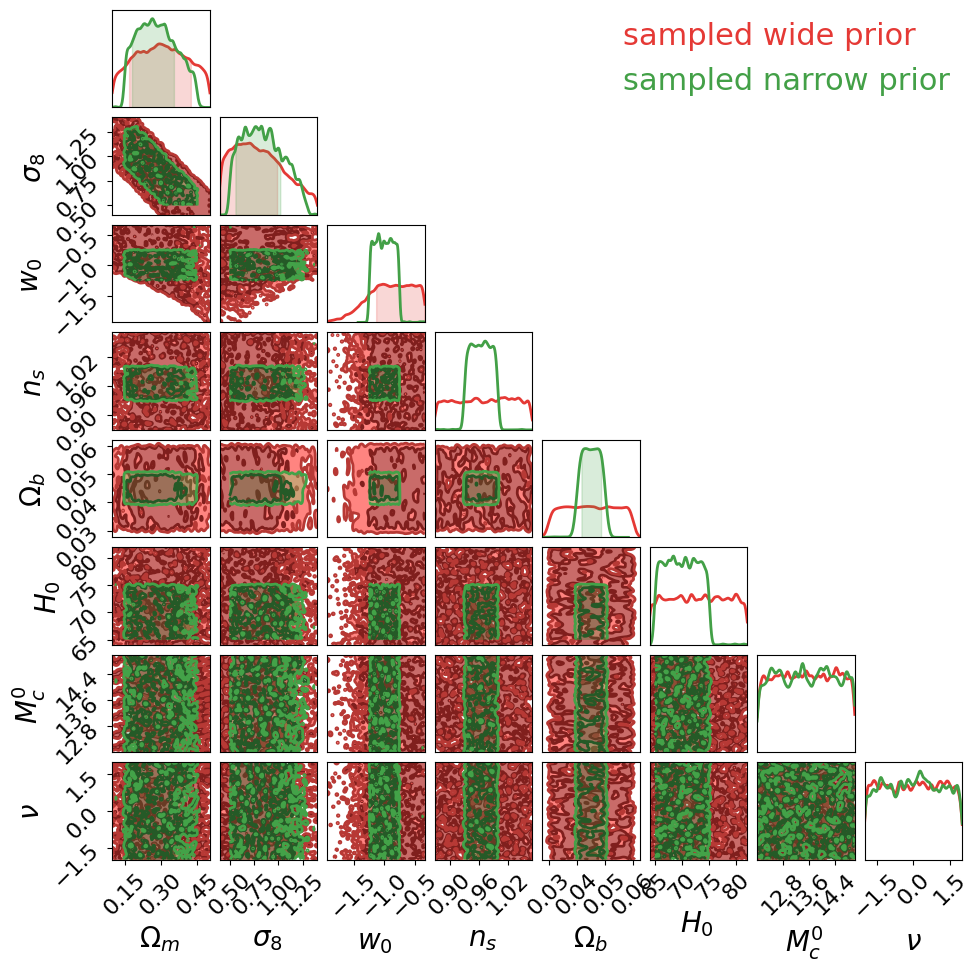

In [61]:
fig = c.plotter.plot(figsize=(10, 10), legend=True)